# Phase-change CNN with 20 explicit random shifts

This notebook inspects the completed `phase_random20_v1` run. Training uses only unscaled sine/cosine of calibrated temporal phase changes, with explicit masks. Every training attempt contributes 20 distinct random shifts within ±0.5 seconds plus its central four-second window; all 21 enter each epoch. The original scenario split stays frozen.

The report describes the exact integer timing contract and preprocessing checks. These are reused within-session test scenarios, not evidence of live detection accuracy. Raw recordings and the earlier experiment remain unchanged.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "06_phase_shifted":
    ROOT = ROOT.parents[2]
RESULTS = ROOT / "notebooks/trash/06_phase_shifted/results/phase_random20_v1"
manifest = json.loads((RESULTS / "manifest.json").read_text())
selection = json.loads((RESULTS / "selection.json").read_text())
evaluation = json.loads((RESULTS / "evaluation.json").read_text())
windows = pd.read_csv(RESULTS / "windows.csv")
print(manifest["representation"])
print("Independent NumPy parity:", manifest["numpy_parity"])
windows.groupby("split").agg(attempts=("attempt_id", "nunique"), scenarios=("scenario_id", "nunique"), windows=("window_index", "size"))


100 ms wrapped calibrated phase difference; sine/cosine before 25 Hz bin means; no smoothing or fitted normalization
Independent NumPy parity: {'windows': 2766, 'maximum_absolute_error': 1.1641532182693481e-10, 'finite_masks_identical': True, 'tolerance': 1e-06}


,attempts,scenarios,windows
split,,,
test,36,21,36
train,128,69,2688
validation,42,22,42


In [2]:
training = windows.loc[windows.split.eq("train")]
assert training.groupby("attempt_id").size().eq(21).all()
assert training.groupby("attempt_id").offset_seconds.nunique().eq(21).all()
assert windows.groupby("scenario_id").split.nunique().eq(1).all()
assert windows.loc[~windows.split.eq("train"), "offset_seconds"].eq(0).all()
assert selection["normalization"] == "none"
shifted = training.loc[~training.central]
print(f"{len(training)} training windows, including {len(shifted)} random shifts")
print("Minimum shifts per training scenario:", shifted.groupby("scenario_id").size().min())
print("Ensemble: mean sigmoid probability of three independently seeded CNNs; threshold 0.5")


2688 training windows, including 2560 random shifts
Minimum shifts per training scenario: 20
Ensemble: mean sigmoid probability of three independently seeded CNNs; threshold 0.5


In [3]:
pd.DataFrame({name: evaluation[name] for name in ["validation", "test"]}).T


,n,accuracy,balanced_accuracy,fall_precision,fall_recall,specificity,fall_f1,roc_auc,average_precision,tn,fp,fn,tp
validation,42.0,0.809524,0.807407,0.705882,0.800000,0.814815,0.750000,0.876543,0.794281,22.0,5.0,3.0,12.0
test,36.0,0.805556,0.770833,0.727273,0.666667,0.875000,0.695652,0.854167,0.636970,21.0,3.0,4.0,8.0


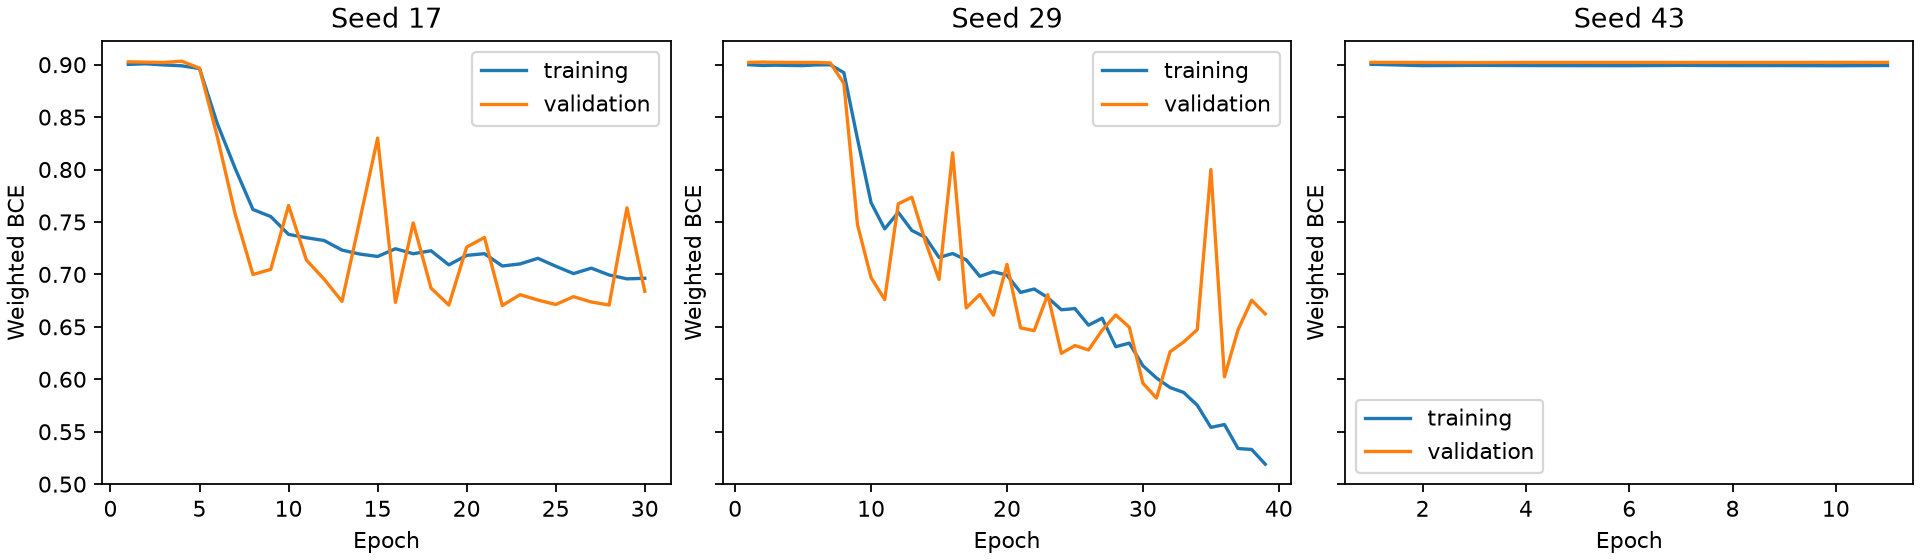

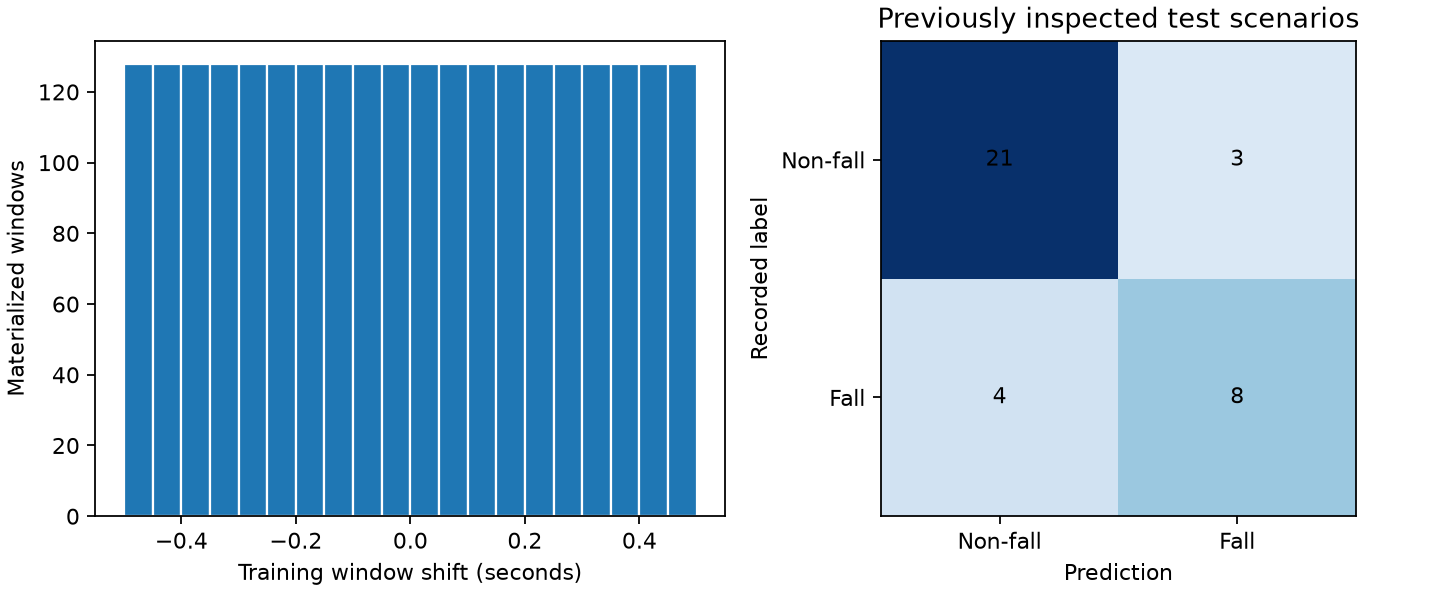

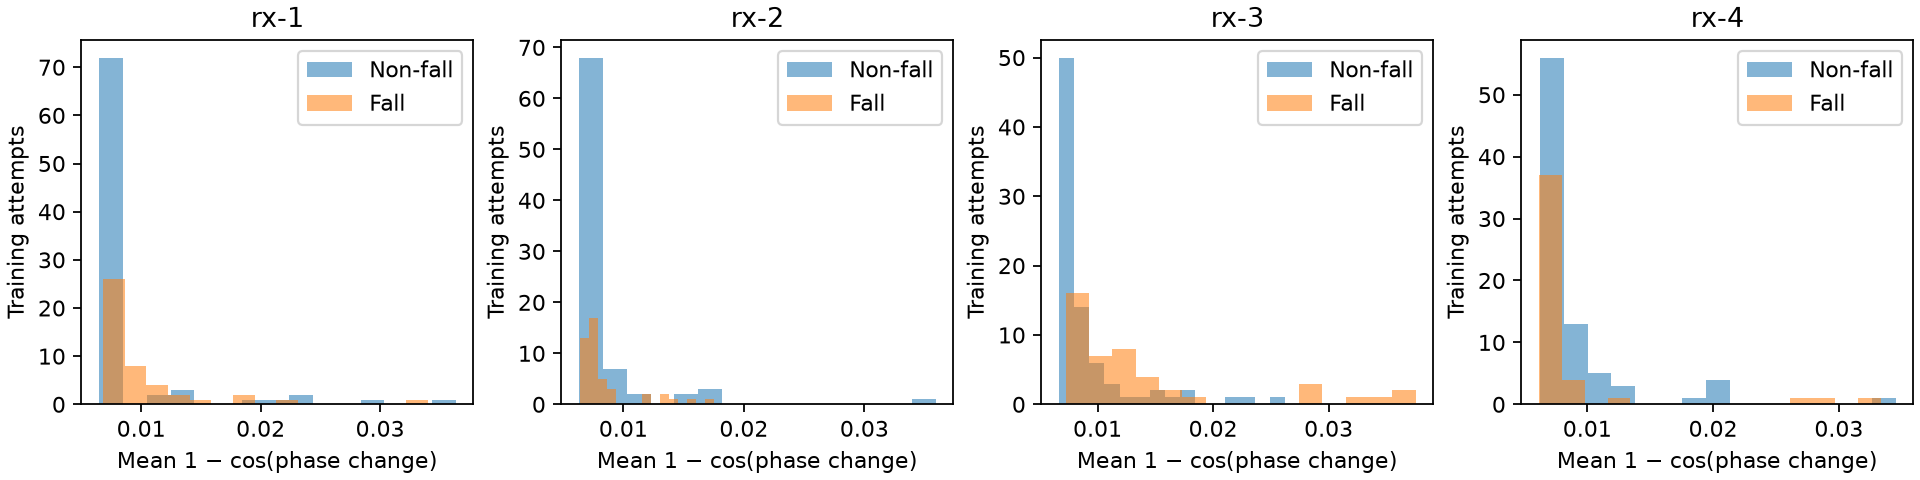

Synthetic stationary phase input: {'probability': 0.26325133442878723, 'seed_probabilities': [0.14354190230369568, 0.14452683925628662, 0.5016852617263794], 'scope': 'Exactly zero phase change with full masks; synthetic diagnostic, not recorded standing accuracy.'}


In [4]:
for filename in ["learning-curves.png", "shifts-and-confusion.png", "training-phase-motion.png"]:
    display(Image(filename=str(RESULTS / filename)))
print("Synthetic stationary phase input:", evaluation["synthetic_stationary_phase"])


Training commands and provenance are documented in [README.md](README.md). Measured results are in [REPORT.md](results/phase_random20_v1/REPORT.md). Low-coverage candidates are replaced with seeded draws; quotas are never silently reduced. Shifted windows are correlated variants of recordings, so the independent sample count remains the number of attempts/scenarios.
